# Two-group RSA: tone-category structure by learning stage

Group-level RSA on FLT2's per-subject, per-stage RDMs (`rsa_roi.py --stage`: crossnobis on GLMsingle single-trial betas; fMRIPrep 25.2.5, T1w). Cross-validation splits each run's repetitions of a stimulus into two halves (`--cv=rep`, FLT2 `trial_splits.py`), not runs: learners change from run to run, and a run split would treat that learning as noise.. Learners (non-Mandarin) vs. native listeners (Mandarin). `09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md`, optional RSA section; structure follows SSP's `GLMsingle_rsa-group.ipynb`, statistics follow `group_stats.py` so they match the univariate and PR results.

Each subject × stage × ROI RDM is compared with two categorical model RDMs (Kendall's tau-a):
- **tone**: same tone = similar. The category the learners learn.
- **talker**: same talker = similar. A non-learned acoustic control.

Sections 2–5: model fits. Section 6: does the geometry change between stages. Section 7: do learners' RDMs become native-like.

Predictions (plan §0): category knowledge → natives' tone fit is present from the early stage; learning → learners' tone fit rises across stages (positive trend), so the groups differ early and converge. Talker fit shouldn't follow that pattern.

Distances are cross-validated Euclidean unless FLT2 ran `--noise=shrinkage` (set `rdm_variant` below). **Before trusting anything here:** FLT2's striatal masking (`--atlas=tian-S2`) and the per-stage RDMs exist for every participant (section 1).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, os.path.join('..', '06_univariate'))
import group_stats as gs
import multivariate_data as mvd

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

bidsroot = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised'
rdm_variant = 'crossnobis_cv-rep'   # or 'crossnobis-noiseshrinkage_cv-rep'; '_cv-run' only for the check in section 1
rdm_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, f'rsa-roi_glmsingle_rdmcalc-{rdm_variant}')
out_dir = os.path.join(mvd.DERIV_DIR, mvd.GLMSINGLE_DIRNAME, 'stats_two-group', f'rsa_{rdm_variant}')
os.makedirs(out_dir, exist_ok=True)

compare_method = 'tau-a'
n_perms, n_boot, seed = 10000, 10000, 0   # matching robustness_checks.py
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}   # as in group_level_two_group.ipynb
labels = {'non-Mandarin': 'learners', 'Mandarin': 'natives'}

## 1. Load and check

In [2]:
participants = mvd.load_participants(bidsroot)
rdms = mvd.load_subject_rdms(rdm_dir, participants)
fits = mvd.add_composites(mvd.model_fits(rdms, participants, method=compare_method))

have = pd.DataFrame(list(rdms), columns=['participant_id', 'stage'])
print('missing a stage:', sorted(set(participants.participant_id) - set(
    have.groupby('participant_id').stage.nunique().loc[lambda n: n == 3].index)))
print('ROIs:', sorted(fits.region_hemi.unique()))
gs.coverage(fits)

missing a stage: []
ROIs: ['L-Association', 'L-Caud', 'L-HG', 'L-IC', 'L-MGN', 'L-PP', 'L-PT', 'L-ParsOp', 'L-ParsTri', 'L-Primary', 'L-Put', 'L-STGa', 'L-STGp', 'NAc-core-lh', 'NAc-core-rh', 'NAc-shell-lh', 'NAc-shell-rh', 'R-Association', 'R-Caud', 'R-HG', 'R-IC', 'R-MGN', 'R-PP', 'R-PT', 'R-ParsOp', 'R-ParsTri', 'R-Primary', 'R-Put', 'R-STGa', 'R-STGp', 'aCAU-lh', 'aCAU-rh', 'aPUT-lh', 'aPUT-rh', 'pCAU-lh', 'pCAU-rh', 'pPUT-lh', 'pPUT-rh']


learning_stage                early  middle  final
contrast   participant_group                      
talker_fit Mandarin              13      13     13
           non-Mandarin          12      12     12
tone_fit   Mandarin              13      13     13
           non-Mandarin          12      12     12

### Check: repetition vs. run split, natives

Natives shouldn't change with learning, so their tone fits from the repetition split and the run split (`rsa_roi.py --cv=run`) should agree. A systematic difference points to noise shared within runs, which the repetition split can't remove. Skipped if the run-split RDMs weren't computed.

In [3]:
run_dir = rdm_dir.replace('_cv-rep', '_cv-run')
if os.path.isdir(run_dir):
    natives = participants[participants.participant_group == 'Mandarin']
    by_split = pd.concat([mvd.model_fits(mvd.load_subject_rdms(d, natives), natives, method=compare_method).assign(cv=cv)
                          for cv, d in [('rep', rdm_dir), ('run', run_dir)]])
    wide = gs.bilateral_mean(by_split.rename(columns={'contrast': 'c'}).assign(contrast=lambda d: d.c + '_' + d.cv))
    wide = wide.pivot_table(index=['participant_id', 'region', 'learning_stage'], columns='contrast', values='beta')
    print('natives, tone fit: repetition minus run split, by stage')
    print((wide['tone_fit_rep'] - wide['tone_fit_run']).groupby('learning_stage').agg(['mean', 'std']).round(3))
else:
    print('no run-split RDMs at', run_dir)

natives, tone fit: repetition minus run split, by stage
                 mean    std
learning_stage              
early           0.001  0.025
final           0.005  0.029
middle          0.002  0.025


### QC: model RDMs and group-mean data RDMs

One ROI, early vs. final. Stimuli are ordered tone-major, so tone structure shows as 4 × 4 blocks on the diagonal.

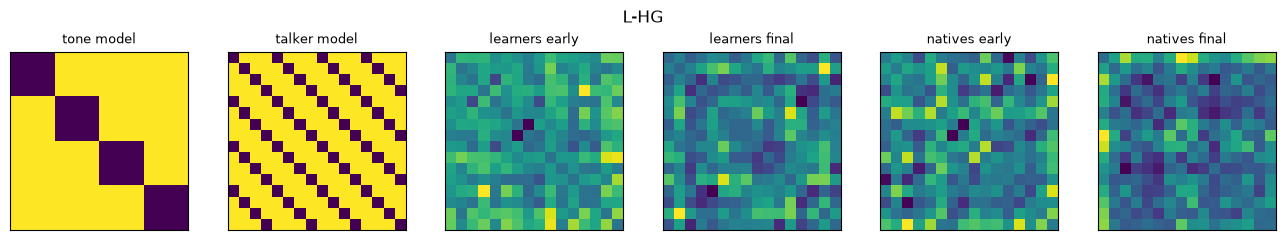

In [4]:
qc_roi = 'L-HG'
vectors, stimuli = mvd.group_mean_rdms(rdms, participants)
models = mvd.model_rdms(stimuli)
order = np.argsort(stimuli)   # tone-major

def square(vector):
    n = len(stimuli)
    m = np.zeros((n, n))
    m[np.triu_indices(n, 1)] = vector
    m = m + m.T
    return m[np.ix_(order, order)]

panels = [(f'{f} model', models[f].get_vectors()[0]) for f in models]
panels += [(f'{labels[g]} {stage}', np.mean(list(vectors[(g, stage, qc_roi)].values()), axis=0))
           for g in gs.GROUPS for stage in ('early', 'final') if (g, stage, qc_roi) in vectors]
fig, axes = plt.subplots(1, len(panels), figsize=(2.2 * len(panels), 2.4))
for ax, (title, vector) in zip(axes, panels):
    ax.imshow(square(vector), cmap='viridis')
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(qc_roi)
fig.tight_layout()

### Noise ceiling

Per group × stage × ROI: lower and upper bounds on the fit any model could reach given between-subject reliability. A low ceiling means that ROI's RDMs are too noisy to interpret a null fit.

In [5]:
ceiling = mvd.noise_ceiling(rdms, participants, method=compare_method)
ceiling.to_csv(os.path.join(out_dir, 'noise_ceiling.tsv'), sep='\t', index=False)
ceiling.pivot_table(index='region_hemi', columns=['participant_group', 'learning_stage'], values='lower').round(3)

participant_group Mandarin               non-Mandarin              
learning_stage       early  final middle        early  final middle
region_hemi                                                        
L-Caud               0.013 -0.014  0.005       -0.029  0.014 -0.001
L-HG                 0.022  0.058  0.027       -0.052  0.028 -0.092
L-IC                -0.006 -0.003  0.034       -0.026 -0.015  0.005
L-MGN               -0.020  0.021 -0.053       -0.037  0.010 -0.030
L-PP                 0.001  0.049 -0.009       -0.051  0.037 -0.073
L-PT                -0.029  0.060 -0.000       -0.033 -0.034  0.053
L-ParsOp             0.036 -0.001  0.042       -0.002 -0.006  0.036
L-ParsTri            0.027  0.031  0.004       -0.015  0.054  0.022
L-Put               -0.001  0.014 -0.036       -0.031 -0.010 -0.018
L-STGa              -0.016  0.008 -0.006        0.022 -0.061  0.046
L-STGp              -0.007  0.023  0.004       -0.055  0.010  0.055
NAc-core-lh          0.041 -0.011 -0.049        0.013  0.044 -0.033
NAc-core-rh          0.055 -0.045 -0.024       -0.008 -0.014 -0.037
NAc-shell-lh        -0.016  0.035 -0.022        0.027 -0.027  0.019
NAc-shell-rh         0.040 -0.007  0.026        0.042 -0.062 -0.041
R-Caud               0.042  0.021  0.012       -0.057  0.077 -0.043
R-HG                -0.020  0.011  0.023       -0.015  0.027  0.004
R-IC                -0.045 -0.000 -0.019        0.028  0.015  0.017
R-MGN               -0.005 -0.011  0.061        0.001 -0.058  0.025
R-PP                -0.067  0.064 -0.033       -0.005  0.077 -0.084
R-PT                -0.017 -0.009  0.004       -0.031  0.029  0.075
R-ParsOp             0.034  0.024  0.005        0.021  0.052  0.011
R-ParsTri           -0.019  0.040  0.018        0.037  0.042  0.044
R-Put                0.045 -0.005 -0.012        0.005 -0.031  0.016
R-STGa               0.048 -0.048 -0.031        0.008 -0.046 -0.025
R-STGp              -0.039 -0.001 -0.025        0.016 -0.038  0.040
aCAU-lh             -0.027  0.025 -0.010        0.007  0.127 -0.014
aCAU-rh             -0.037 -0.019  0.014       -0.039  0.053 -0.015
aPUT-lh              0.002  0.036 -0.002       -0.002 -0.037 -0.038
aPUT-rh             -0.012 -0.024 -0.020       -0.016 -0.008 -0.003
pCAU-lh             -0.005  0.051 -0.030       -0.034  0.041 -0.087
pCAU-rh              0.007  0.034 -0.012        0.002  0.047  0.000
pPUT-lh              0.006 -0.026 -0.053       -0.055 -0.018 -0.022
pPUT-rh              0.051 -0.011  0.019       -0.053  0.007  0.009

## 2. Model fits by stage and group

Hemispheres averaged per participant; mean ± SEM.

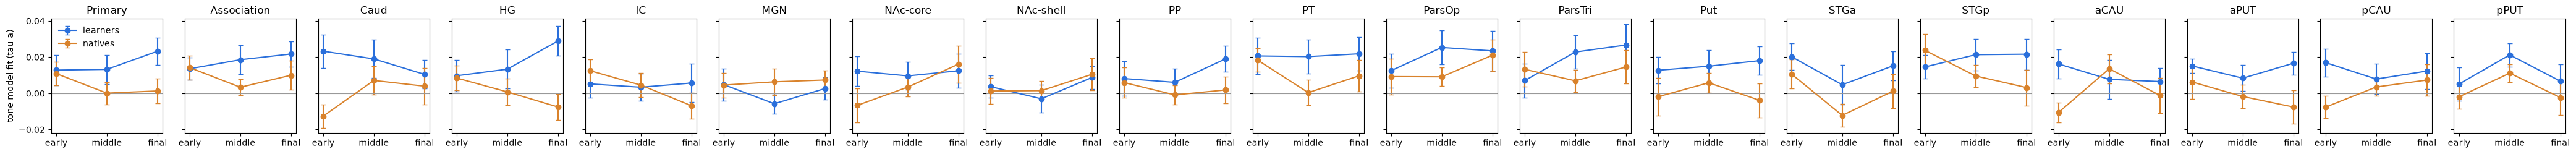

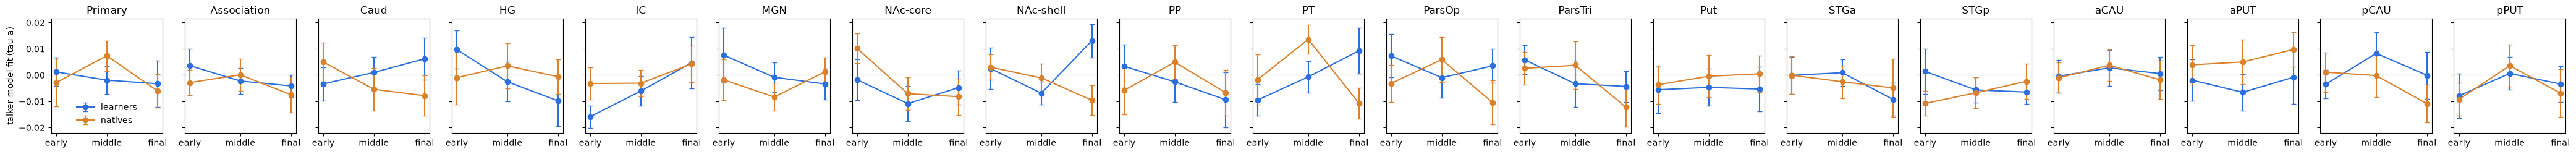

In [6]:
bilat = gs.bilateral_mean(fits)
regions = list(mvd.COMPOSITES) + sorted(r for r in bilat.region.unique() if r not in mvd.COMPOSITES)
for factor in mvd.STIMULUS_FACTORS:
    sub = bilat[bilat.contrast == f'{factor}_fit']
    fig, axes = plt.subplots(1, len(regions), figsize=(2.2 * len(regions), 2.6), sharey=True)
    for ax, region in zip(np.atleast_1d(axes), regions):
        for group in gs.GROUPS:
            g = sub[(sub.region == region) & (sub.participant_group == group)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', capsize=3, color=colors[group], label=labels[group])
        ax.axhline(0, color='0.6', lw=0.8)
        ax.set_xticks(range(3), gs.STAGE_ORDER)
        ax.set_title(region)
    np.atleast_1d(axes)[0].set_ylabel(f'{factor} model fit (tau-a)')
    np.atleast_1d(axes)[0].legend(frameon=False)
    fig.tight_layout()

## 3. Is there category structure? Fit vs. 0 within each group

Per stage and stages averaged; FDR across regions within group × model × network (× stage).

In [7]:
baseline = gs.baseline_tests(fits)
baseline_by_stage = gs.baseline_tests(fits, by_stage=True)
baseline.to_csv(os.path.join(out_dir, 'fit_vs_0.tsv'), sep='\t', index=False)
baseline_by_stage.to_csv(os.path.join(out_dir, 'fit_vs_0_by-stage.tsv'), sep='\t', index=False)
baseline_by_stage[baseline_by_stage.contrast == 'tone_fit'].pivot_table(
    index=['network', 'region'], columns=['participant_group', 'learning_stage'], values='t').round(2)

participant_group              Mandarin              non-Mandarin             
learning_stage                    early final middle        early final middle
network            region                                                     
auditory           HG              1.25 -1.04   0.10         1.10  3.49   1.24
                   PP              0.70  0.26  -0.16         0.84  2.65   0.81
                   PT              2.80  1.12   0.05         2.02  2.38   2.19
                   ParsOp          0.94  2.41   1.75         1.33  2.11   2.71
                   ParsTri         1.39  1.58   1.11         0.74  2.29   2.47
                   STGa            1.31  0.12  -1.91         2.77  1.89   0.43
                   STGp            2.62  0.32   1.54         2.23  2.52   2.46
auditory-composite Association     2.13  1.24   0.74         2.21  3.06   2.33
                   Primary         1.71  0.19   0.01         1.52  3.07   1.64
striatum-whole     Caud           -1.98  0.39   0.91         2.51  1.33   1.78
                   Put            -0.18 -0.41   1.05         1.72  2.28   1.66
subcort-aud        IC              1.95 -0.96   0.68         0.69  0.53   0.45
                   MGN             0.66  1.41   0.86         0.54  0.43  -1.02
tian-S2            NAc-core       -0.72  1.56   0.64         1.52  1.31   1.27
                   NAc-shell       0.18  1.18   0.27         0.61  1.39  -0.40
                   aCAU           -1.97 -0.12   1.70         2.05  0.88   0.71
                   aPUT            0.67 -0.82  -0.27         3.78  2.61   1.16
                   pCAU           -1.23  0.84   0.69         2.21  1.25   0.94
                   pPUT           -0.29 -0.24   2.23         0.55  0.71   3.24

## 4. Does tone structure emerge with learning? Trend, learners vs. natives

Per-participant `[-1, 0, 1]` trend (final − early) in tone fit, compared between groups. The full battery (sign-flip, LOSO, bootstrap, group-label permutation) runs on the composites and the two striatal regions of the univariate headline (aCAU, aPUT); every region gets the Welch/permutation test with FDR. Talker fit alongside as the control -- but the fits aren't independent: tau-a is rank-based, so as tone structure grows, the same RDM ranks talker pairs lower and talker fit falls even if talker information is unchanged (seen in synthetic data). Read a talker-fit decline next to a tone-fit rise as a shift in relative structure, not lost talker information; a model fitting both at once (e.g. rsatoolbox `ModelWeighted` with tone and talker components) would separate them. Exploratory: no RSA test was pre-specified.

In [8]:
trends = gs.subject_trends(fits)
focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(trends.region)]
battery = pd.concat([gs.trend_group_difference(trends, f'{factor}_fit', region,
                                               n_perms=n_perms, n_boot=n_boot, seed=seed)
                     for factor in mvd.STIMULUS_FACTORS for region in focus], ignore_index=True)
battery.to_csv(os.path.join(out_dir, 'fit_trend_focus-regions.tsv'), sep='\t', index=False)
battery.round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.010,0.902,0.386,0.387,0/12,-0.011,0.032,tone_fit,Primary
1,Mandarin trend vs 0,13,-0.010,-1.242,0.238,0.252,0/13,-0.025,0.004,tone_fit,Primary
2,non-Mandarin - Mandarin (Welch),25,0.020,1.440,0.166,0.156,0/25,-0.006,0.047,tone_fit,Primary
3,non-Mandarin trend vs 0,12,0.008,0.906,0.385,0.377,0/12,-0.009,0.025,tone_fit,Association
4,Mandarin trend vs 0,13,-0.004,-0.451,0.660,0.654,0/13,-0.022,0.013,tone_fit,Association
5,non-Mandarin - Mandarin (Welch),25,0.012,0.953,0.351,0.354,0/25,-0.012,0.036,tone_fit,Association
6,non-Mandarin trend vs 0,12,-0.010,-0.741,0.474,0.464,0/12,-0.034,0.015,tone_fit,aCAU
7,Mandarin trend vs 0,13,0.009,0.817,0.430,0.438,0/13,-0.011,0.032,tone_fit,aCAU
8,non-Mandarin - Mandarin (Welch),25,-0.019,-1.095,0.285,0.290,0/25,-0.053,0.013,tone_fit,aCAU
9,non-Mandarin trend vs 0,12,0.001,0.178,0.862,0.863,0/12,-0.015,0.016,tone_fit,aPUT


In [9]:
per_region = fits[~fits.region.isin(mvd.COMPOSITES)]
trend_diff = gs.trend_difference_tests(gs.subject_trends(per_region),
                                       contrasts=[f'{f}_fit' for f in mvd.STIMULUS_FACTORS],
                                       n_perms=n_perms, seed=seed)
trend_diff.to_csv(os.path.join(out_dir, 'fit_trend_group-difference.tsv'), sep='\t', index=False)
trend_diff.round(3)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,d_ci_lower,d_ci_upper,permutation_p,q
0,auditory,talker_fit,HG,12,13,-0.020,0.000,-0.020,-1.534,0.139,-0.611,-1.413,0.192,0.136,0.324
1,auditory,talker_fit,PP,12,13,-0.013,-0.001,-0.012,-0.800,0.433,-0.324,-1.113,0.466,0.422,0.757
2,auditory,talker_fit,PT,12,13,0.019,-0.009,0.028,1.809,0.084,0.726,-0.084,1.537,0.081,0.324
3,auditory,talker_fit,ParsOp,12,13,-0.004,-0.007,0.003,0.235,0.817,0.092,-0.693,0.877,0.827,0.817
4,auditory,talker_fit,ParsTri,12,13,-0.010,-0.015,0.005,0.407,0.688,0.160,-0.626,0.946,0.722,0.817
5,auditory,talker_fit,STGa,12,13,-0.009,-0.005,-0.004,-0.288,0.776,-0.115,-0.900,0.671,0.778,0.817
6,auditory,talker_fit,STGp,12,13,-0.008,0.008,-0.016,-1.611,0.121,-0.647,-1.452,0.158,0.119,0.324
7,auditory,tone_fit,HG,12,13,0.019,-0.016,0.035,2.523,0.020,1.023,0.188,1.857,0.016,0.125
8,auditory,tone_fit,PP,12,13,0.011,-0.004,0.015,0.974,0.341,0.393,-0.400,1.185,0.334,0.691
9,auditory,tone_fit,PT,12,13,0.001,-0.009,0.010,0.546,0.591,0.221,-0.566,1.008,0.580,0.827


## 5. Do natives start ahead and learners catch up? Group difference per stage

Learners − natives per stage (negative = natives higher). The category-knowledge prediction is a negative difference early that shrinks by the final stage. FDR across regions within model × network × stage.

In [10]:
stage_diff = gs.group_difference_tests(per_region, contrasts=[f'{f}_fit' for f in mvd.STIMULUS_FACTORS],
                                       by_stage=True, n_perms=n_perms, seed=seed)
stage_diff.to_csv(os.path.join(out_dir, 'fit_group-difference_by-stage.tsv'), sep='\t', index=False)
stage_diff[stage_diff.contrast == 'tone_fit'].pivot_table(
    index=['network', 'region'], columns='learning_stage', values='d')[list(gs.STAGE_ORDER)].round(2)

learning_stage            early  middle  final
network        region                         
auditory       HG          0.05    0.39   1.33
               PP          0.07    0.30   0.67
               PT          0.08    0.69   0.39
               ParsOp      0.10    0.62   0.07
               ParsTri    -0.19    0.58   0.33
               STGa        0.35    0.55   0.45
               STGp       -0.32    0.45   0.56
striatum-whole Caud        1.29    0.36   0.20
               Put         0.45    0.35   0.71
subcort-aud    IC         -0.30   -0.05   0.40
               MGN         0.01   -0.52  -0.23
tian-S2        NAc-core    0.61    0.27  -0.10
               NAc-shell   0.10   -0.20  -0.06
               aCAU        1.14   -0.18   0.25
               aPUT        0.34    0.42   0.85
               pCAU        1.01    0.18   0.15
               pPUT        0.25    0.49   0.27

In [11]:
anova = gs.group_by_stage_anova(per_region)
anova.to_csv(os.path.join(out_dir, 'fit_group-by-stage-anova.tsv'), sep='\t', index=False)
anova[anova.q < .05].round(3)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q


## 6. Does the representation change? Stage-to-stage RDM stability

Within each participant and ROI, the correlation between two stages' RDMs (early–middle, middle–final, early–final). This tests whether the geometry changes, not just how strongly tone is represented. Prediction: natives are stable throughout. Learners change, so early–final < middle–final as their representation settles. Learners − natives per stage pair (FDR across regions within network × pair), plus learners' within-group comparison of the early–final and middle–final pairs.

**Check:** a noisier RDM correlates less with anything, so low early stability could mean a noisy early RDM rather than change. The mean cross-validated distance per stage is tested the same way. A stability difference matched by a distance difference in the same direction isn't evidence of change.

In [12]:
stability = mvd.add_composites(mvd.stage_stability(rdms, participants))
distance = mvd.add_composites(mvd.mean_distance(rdms, participants))

stability_diff = gs.group_difference_tests(stability[~stability.region.isin(mvd.COMPOSITES)],
                                           contrasts=('stage_stability',), by_stage=True, n_perms=n_perms, seed=seed)
stability_diff.to_csv(os.path.join(out_dir, 'stage-stability_group-difference.tsv'), sep='\t', index=False)

# learners: does stability rise as the representation settles? (paired, per region, composites included)
bilat_stab = gs.bilateral_mean(stability)
learners_stab = bilat_stab[bilat_stab.participant_group == 'non-Mandarin'].pivot_table(
    index=['region', 'participant_id'], columns='learning_stage', values='beta')
settling = (learners_stab['middle-final'] - learners_stab['early-final']).groupby('region').agg(
    ['mean', 'count', lambda x: stats.ttest_1samp(x, 0).pvalue]).set_axis(['mean', 'n', 'p'], axis=1)
print('learners, middle-final minus early-final stability:')
print(settling.round(3))
stability_diff.pivot_table(index=['network', 'region'], columns='learning_stage', values='d').round(2)

learners, middle-final minus early-final stability:
              mean   n      p
region                       
Association -0.010  12  0.718
Caud         0.087  12  0.196
HG           0.017  12  0.747
IC           0.029  12  0.332
MGN          0.004  12  0.924
NAc-core     0.020  12  0.632
NAc-shell   -0.004  12  0.947
PP           0.049  12  0.341
PT           0.041  12  0.400
ParsOp       0.016  12  0.739
ParsTri     -0.093  12  0.062
Primary      0.036  12  0.387
Put          0.066  12  0.165
STGa        -0.043  12  0.219
STGp         0.078  12  0.091
aCAU         0.075  12  0.187
aPUT         0.065  12  0.089
pCAU         0.127  12  0.025
pPUT         0.101  12  0.046


learning_stage            early-final  early-middle  middle-final
network        region                                            
auditory       HG                0.11         -0.31          0.62
               PP                0.07         -0.26          0.30
               PT                0.50         -0.06          0.39
               ParsOp            0.14          0.59          0.06
               ParsTri           0.87          0.16         -0.24
               STGa             -0.16          0.31         -0.34
               STGp              0.48         -0.19          0.80
striatum-whole Caud             -0.30          0.03          0.59
               Put              -0.44          0.04         -0.09
subcort-aud    IC                0.18         -0.17         -0.14
               MGN               0.19          0.06         -0.27
tian-S2        NAc-core         -0.20          0.33         -0.14
               NAc-shell         0.01         -0.13          0.18
               aCAU             -0.24          0.35          0.33
               aPUT             -0.54         -0.50         -0.21
               pCAU             -0.35         -0.21          0.44
               pPUT             -0.52          0.20          0.29

In [13]:
# signal-strength check: mean cross-validated distance, learners - natives per stage
distance_diff = gs.group_difference_tests(distance[~distance.region.isin(mvd.COMPOSITES)],
                                          contrasts=('mean_distance',), by_stage=True, n_perms=n_perms, seed=seed)
distance_diff.to_csv(os.path.join(out_dir, 'mean-distance_group-difference_by-stage.tsv'), sep='\t', index=False)
distance_diff.pivot_table(index=['network', 'region'], columns='learning_stage', values='d')[list(gs.STAGE_ORDER)].round(2)

learning_stage            early  middle  final
network        region                         
auditory       HG          0.86    0.03  -0.16
               PP         -0.04    0.07  -0.19
               PT         -0.20   -0.39  -0.06
               ParsOp     -0.61    0.66   0.25
               ParsTri     0.28   -0.44   0.44
               STGa        0.30   -0.05  -0.47
               STGp        0.48   -0.27   0.25
striatum-whole Caud       -0.22   -0.41  -0.49
               Put        -0.11    0.18  -0.10
subcort-aud    IC          0.31   -0.21  -0.18
               MGN        -0.32    0.27  -0.33
tian-S2        NAc-core   -0.42    0.08  -0.36
               NAc-shell  -0.21   -0.33  -0.51
               aCAU        0.06   -0.10  -0.09
               aPUT       -0.29   -0.09   0.04
               pCAU       -0.22   -0.17  -0.06
               pPUT       -0.15    0.28   0.06

## 7. Do learners become native-like? Similarity to the natives' RDM

Each participant's RDM per stage, correlated with the natives' template: their mean RDM over all stages, each native left out of their own template. Prediction: learners' native-likeness rises across stages (positive trend); natives' (their leave-one-out values, effectively a noise ceiling) stays flat.

**Control, peer-likeness:** correlation with the mean of the participant's own group at the same stage. Cleaner RDMs correlate more with everything, so learners' native-likeness should rise *more* than their peer-likeness for convergence on the native geometry. Tested per participant as the trend in native- minus peer-likeness.

In [14]:
likeness = mvd.add_composites(mvd.native_likeness(rdms, participants))
likeness_trends = gs.subject_trends(likeness)
focus = [r for r in list(mvd.COMPOSITES) + ['aCAU', 'aPUT'] if r in set(likeness_trends.region)]
native_battery = pd.concat([gs.trend_group_difference(likeness_trends, 'native_likeness', region,
                                                      n_perms=n_perms, n_boot=n_boot, seed=seed)
                            for region in focus], ignore_index=True)

# convergence beyond reliability: trend in native- minus peer-likeness
wide = likeness_trends.pivot_table(index=['network', 'participant_id', 'participant_group', 'region'],
                                   columns='contrast', values='trend').dropna()
beyond = (wide['native_likeness'] - wide['peer_likeness']).rename('trend').reset_index().assign(
    contrast='native_minus_peer')
beyond_battery = pd.concat([gs.trend_group_difference(beyond, 'native_minus_peer', region,
                                                      n_perms=n_perms, n_boot=n_boot, seed=seed)
                            for region in focus], ignore_index=True)
pd.concat([native_battery, beyond_battery]).to_csv(os.path.join(out_dir, 'native-likeness_trend.tsv'),
                                                   sep='\t', index=False)
pd.concat([native_battery, beyond_battery]).round(3)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,0.021,0.701,0.498,0.490,0/12,-0.034,0.076,native_likeness,Primary
1,Mandarin trend vs 0,13,0.062,2.094,0.058,0.060,3/13,0.006,0.117,native_likeness,Primary
2,non-Mandarin - Mandarin (Welch),25,-0.041,-0.990,0.332,0.327,0/25,-0.121,0.036,native_likeness,Primary
3,non-Mandarin trend vs 0,12,0.048,1.930,0.080,0.081,2/12,0.002,0.094,native_likeness,Association
4,Mandarin trend vs 0,13,-0.008,-0.274,0.789,0.788,0/13,-0.063,0.044,native_likeness,Association
5,non-Mandarin - Mandarin (Welch),25,0.056,1.478,0.153,0.155,0/25,-0.014,0.129,native_likeness,Association
6,non-Mandarin trend vs 0,12,-0.026,-0.893,0.391,0.383,0/12,-0.078,0.029,native_likeness,aCAU
7,Mandarin trend vs 0,13,0.017,0.465,0.650,0.641,0/13,-0.052,0.083,native_likeness,aCAU
8,non-Mandarin - Mandarin (Welch),25,-0.042,-0.920,0.368,0.369,0/25,-0.127,0.046,native_likeness,aCAU
9,non-Mandarin trend vs 0,12,-0.020,-0.483,0.639,0.628,0/12,-0.097,0.060,native_likeness,aPUT


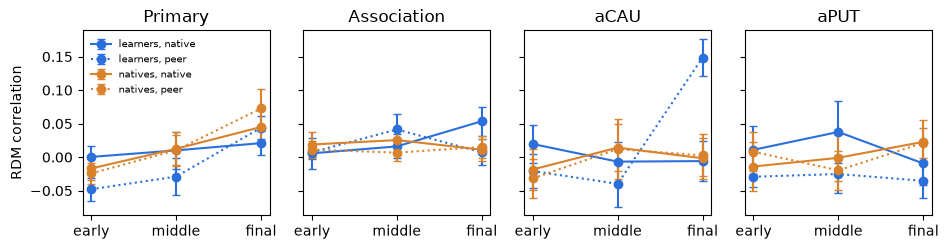

In [15]:
bilat_like = gs.bilateral_mean(likeness)
fig, axes = plt.subplots(1, len(focus), figsize=(2.4 * len(focus), 2.6), sharey=True)
for ax, region in zip(np.atleast_1d(axes), focus):
    for group in gs.GROUPS:
        for contrast, ls in [('native_likeness', '-'), ('peer_likeness', ':')]:
            g = bilat_like[(bilat_like.region == region) & (bilat_like.participant_group == group)
                           & (bilat_like.contrast == contrast)].groupby('learning_stage').beta
            ax.errorbar(range(3), g.mean().reindex(gs.STAGE_ORDER), yerr=g.sem().reindex(gs.STAGE_ORDER),
                        marker='o', ls=ls, capsize=3, color=colors[group],
                        label=f"{labels[group]}, {contrast.split('_')[0]}")
    ax.set_xticks(range(3), gs.STAGE_ORDER)
    ax.set_title(region)
np.atleast_1d(axes)[0].set_ylabel('RDM correlation')
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7)
fig.tight_layout()

## 8. Export

Per-participant fit trends for integration with the striatal and PR results (plan R7).

In [16]:
trends.to_csv(os.path.join(out_dir, 'fit_trend_scalars.tsv'), sep='\t', index=False)
fits.to_csv(os.path.join(out_dir, 'model_fits.tsv'), sep='\t', index=False)
print('wrote', out_dir)
stability.to_csv(os.path.join(out_dir, 'stage_stability.tsv'), sep='\t', index=False)
likeness.to_csv(os.path.join(out_dir, 'native_likeness.tsv'), sep='\t', index=False)

wrote /ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/glmsingle_fmriprep-25.2.5_space-T1w/stats_two-group/rsa_crossnobis_cv-rep
